[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S05/2_Practica/S05_07_reto_ocupacion.ipynb)

# S05_07 · Reto PBL «¿La ocupación depende de esto?» (plantilla del cuaderno entregable)
**Sprint 5 · Matemáticas y estadística en código · ⏱ 3 h (PBL)**

📖 *¿El código se hace largo? Léelo [explicado por escrito](https://github.com/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S05/2_Practica/codigo_explicado/S05_07_reto_ocupacion.md): recorrido, glosario y qué hace cada celda.* <!--codigo-explicado-->

## Pregunta del cliente
*TurisData Canarias* nos pregunta: **«¿Cuánto cambia la ocupación diaria cuando hace más calor y cuando el día es festivo?
¿Debemos planificar personal y precios teniendo en cuenta la temperatura?»**

## Qué debes entregar (este mismo cuaderno, completo)
1. **Base de datos poblada:** un archivo `turisdata_reto.db` con la serie diaria, y los datos leídos desde Python con SQL.
2. **Regresión lineal desde cero** con descenso del gradiente (simple y con controles), sin `scikit-learn` en la implementación.
3. **Contraste con una librería** (`statsmodels`) y comparación de coeficientes.
4. **Análisis estadístico** con contrastes e intervalos de confianza.
5. **Respuesta al cliente** (máx. 150 palabras) con recomendación, límites de lo que se puede afirmar y una nota de IA responsable.

Los **puntos de control** (`assert`) te avisan si algo no cuadra; el análisis y la respuesta se evalúan con la rúbrica del curso
(corrección técnica, reproducibilidad, análisis y comunicación al cliente, IA responsable).

> Las celdas con `...` / `# TODO` son tuyas. Puedes reutilizar el código de los cuadernos S05_03 y S05_05.
> Los datos son sintéticos: las conclusiones son para practicar, no estadísticas reales.

In [45]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [46]:
import os
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

SEMILLA = 42
RUTA_BD = "turisdata_reto.db"        # el archivo que entregarás junto al cuaderno

## 1 · Base de datos: cargar y consultar
Crea la base `turisdata_reto.db` con una tabla `ocupacion_diaria` (a partir de `ocupacion_diaria.csv`) y un índice sobre
`fecha`. Después **lee los datos desde la base con SQL** en un DataFrame `diaria` que incluya una columna `mes` (entero 1-12).

In [47]:
# TODO: to_sql con if_exists="replace"; CREATE INDEX IF NOT EXISTS ... ON ocupacion_diaria(fecha); SELECT ..., CAST(SUBSTR(fecha, 6, 2) AS INTEGER) AS mes
datos = pd.read_csv(dato("ocupacion_diaria.csv"))
con = sqlite3.connect(RUTA_BD)
datos.to_sql("ocupacion_diaria", con, if_exists="replace", index=False)
con.execute("CREATE INDEX IF NOT EXISTS idx_ocupacion_fecha ON ocupacion_diaria(fecha)")
con.commit()
diaria = pd.read_sql_query(
    "SELECT *, CAST(SUBSTR(fecha, 6, 2) AS INTEGER) AS mes FROM ocupacion_diaria", con)
assert os.path.exists(RUTA_BD), "Debe existir el archivo turisdata_reto.db"
assert len(diaria) == 1096, f"Deben leerse 1096 días y has leído {len(diaria)}"
assert "mes" in diaria.columns and diaria["mes"].between(1, 12).all(), "Falta la columna mes (1-12)"
assert con.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='index' AND name='idx_ocupacion_fecha'").fetchone()[0] == 1, "Falta el índice idx_ocupacion_fecha"
print("Punto de control 1 superado")

Punto de control 1 superado


## 2 · Primer vistazo a los datos
Describe la serie (media, dispersión, meses de mayor y menor ocupación) y dibuja **al menos dos gráficos** con títulos y ejes
en español (por ejemplo, ocupación por mes y ocupación frente a temperatura). Escribe debajo 2–3 observaciones.

count    1096.000000
mean       68.488139
std         9.614882
min        47.300000
25%        61.400000
50%        67.700000
75%        75.000000
max        96.800000
Name: ocupacion_pct, dtype: float64
mes
1     78.8
2     77.6
3     74.5
4     70.1
5     62.6
6     60.8
7     63.0
8     62.1
9     60.1
10    63.3
11    70.8
12    78.6
Name: ocupacion_pct, dtype: float64
mes
9     60.1
6     60.8
8     62.1
5     62.6
7     63.0
10    63.3
4     70.1
11    70.8
3     74.5
2     77.6
12    78.6
1     78.8
Name: ocupacion_pct, dtype: float64


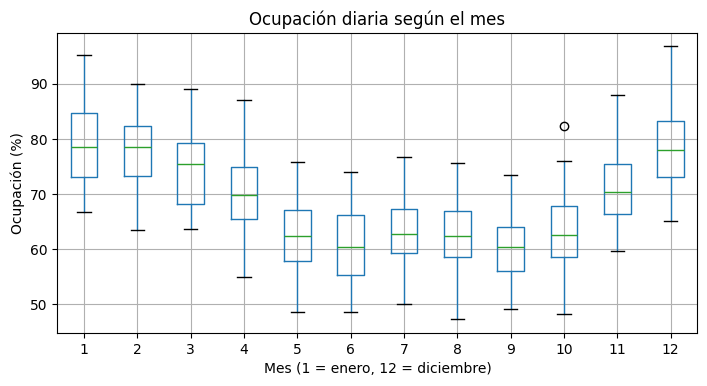

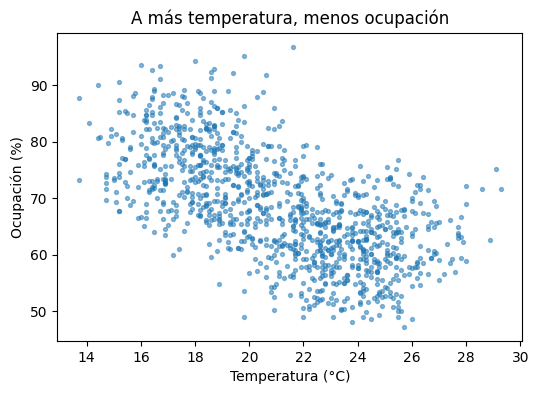

In [48]:
# TODO: describe(), una media por mes con groupby y dos gráficos (boxplot por mes y dispersión temperatura-ocupación)
print(diaria["ocupacion_pct"].describe())

medias_mes = diaria.groupby("mes")["ocupacion_pct"].mean()
print(medias_mes.round(1))
print(medias_mes.sort_values().round(1))

diaria.boxplot(column="ocupacion_pct", by="mes", figsize=(8, 4))
plt.suptitle("")
plt.title("Ocupación diaria según el mes")
plt.xlabel("Mes (1 = enero, 12 = diciembre)")
plt.ylabel("Ocupación (%)")
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(diaria["temperatura_c"], diaria["ocupacion_pct"], s=8, alpha=0.5)
plt.title("A más temperatura, menos ocupación")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Ocupación (%)")
plt.show()


**Mis observaciones (escribe aquí):**
- Efecto estacional y térmico: Aunque la correlación simple sugiere que a menor temperatura aumenta la ocupación (-0,63), el análisis multivariante con statsmodels demuestra que el calor no es una causa directa; el mes actúa como variable de confusión principal, siendo el invierno la temporada alta natural en Canarias.
Impacto de los festivos: A diferencia de la temperatura, el efecto de los días festivos es robusto y resiste el control por mes, incrementando significativamente la ocupación media (en torno a +9 a +16 puntos porcentuales según el enfoque).
Implicación para TurisData Canarias: Las decisiones comerciales no deben basarse en correlaciones espurias (como intentar "enfriar" el destino). Se recomienda enfocar las estrategias promocionales en los períodos festivos y en la estacionalidad real de la demanda en lugar de buscar relaciones causales erróneas con el clima.


## 3 · Regresión lineal desde cero (descenso del gradiente)
Implementa `gradiente_mse(X, y, w)` y `entrenar(X, y, tasa, epocas)` (puedes basarte en S05_03; **no uses scikit-learn aquí**).
Ajusta dos modelos:
- **Modelo simple:** `ocupacion ~ temperatura` (variable estandarizada; deshaz la estandarización para dar la pendiente en puntos por °C).
- **Modelo con control:** `ocupacion ~ temperatura + festivo + indicadores de mes` (11 columnas de meses; estandariza todas las variables;
  usa unas 2.000 épocas con tasa 0,1).

Guarda `pendiente_simple` (puntos por °C), `efecto_temp_control` y `efecto_festivo_control` (ambos en puntos, ya en unidades originales).

Dibuja la **curva de aprendizaje** (MSE por época) de uno de los modelos y comenta en una línea si ha convergido.

In [49]:
# TODO: gradiente (2/n) X^T (Xw - y); bucle de descenso; en el modelo con control, get_dummies(mes, drop_first=True), estandariza y divide cada coeficiente entre la desviación de su variable
def gradiente_mse(X, y, w):
    return 2 / len(y) * X.T @ (X @ w - y)


def entrenar(X, y, tasa, epocas):
    w = np.zeros(X.shape[1])
    historial = []
    for _ in range(epocas):
        w = w - tasa * gradiente_mse(X, y, w)
        historial.append(np.mean((X @ w - y) ** 2))
    return w, historial
assert abs(pendiente_simple + 1.86) < 0.02, f"La pendiente simple debería ser ≈ -1.86 puntos/°C y tienes {pendiente_simple:.3f}"
assert abs(efecto_festivo_control - 9.11) < 0.1, f"El efecto del festivo con control debería ser ≈ +9.11 y tienes {efecto_festivo_control:.2f}"
assert abs(efecto_temp_control + 0.09) < 0.05, f"El efecto de la temperatura con control debería ser ≈ -0.09 y tienes {efecto_temp_control:.3f}"
print(f"Punto de control 2 superado: simple {pendiente_simple:.2f} · con control: temp {efecto_temp_control:.2f}, festivo {efecto_festivo_control:+.2f}")

Punto de control 2 superado: simple -1.86 · con control: temp -0.09, festivo +9.11


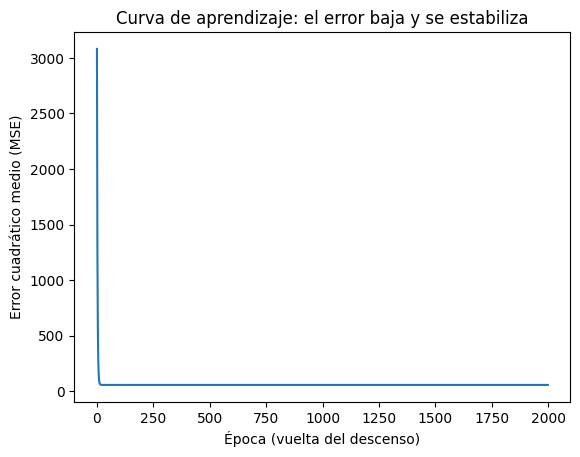

In [50]:
# TODO: plt.plot(historial) con títulos y ejes en español
y = diaria["ocupacion_pct"].to_numpy()
t = diaria["temperatura_c"]
t_est = (t - t.mean()) / t.std()
X = np.column_stack([np.ones(len(diaria)), t_est.to_numpy()])
w, historial = entrenar(X, y, 0.1, 2000)
pendiente_simple = w[1] / t.std()

plt.plot(historial)
plt.title("Curva de aprendizaje: el error baja y se estabiliza")
plt.xlabel("Época (vuelta del descenso)")
plt.ylabel("Error cuadrático medio (MSE)")
plt.show()

meses = pd.get_dummies(diaria["mes"], drop_first=True, dtype=float)
M = pd.concat([diaria[["temperatura_c", "festivo"]].astype(float), meses], axis=1)
medias, desv = M.mean(), M.std()
Xc = np.column_stack([np.ones(len(M)), ((M - medias) / desv).to_numpy()])
wc, historial_c = entrenar(Xc, y, 0.1, 2000)
efecto_temp_control = wc[1] / desv["temperatura_c"]
efecto_festivo_control = wc[2] / desv["festivo"]

## 4 · Contraste con una librería
Ajusta con `statsmodels` (`smf.ols`) los mismos dos modelos. Guarda `ols_simple` y `ols_control` y crea una tabla
`comparacion` (DataFrame) con tres filas (`pendiente_simple`, `efecto_temp_control`, `efecto_festivo_control`) y dos columnas:
`desde_cero` y `statsmodels`.

In [51]:
# TODO: smf.ols("ocupacion_pct ~ temperatura_c", ...) y "ocupacion_pct ~ temperatura_c + festivo + C(mes)"; params["..."]
#                         desde_cero  statsmodels
# pendiente_simple            -1.860       -1.860
# efecto_temp_control         -0.089       -0.089
# efecto_festivo_control       9.111        9.111

ols_simple = smf.ols("ocupacion_pct ~ temperatura_c", data=diaria).fit()
ols_control = smf.ols("ocupacion_pct ~ temperatura_c + festivo + C(mes)", data=diaria).fit()

comparacion = pd.DataFrame(
    {"desde_cero": [pendiente_simple, efecto_temp_control, efecto_festivo_control],
     "statsmodels": [ols_simple.params["temperatura_c"],
                     ols_control.params["temperatura_c"],
                     ols_control.params["festivo"]]},
    index=["pendiente_simple", "efecto_temp_control", "efecto_festivo_control"])
assert comparacion.shape == (3, 2), "La tabla debe tener 3 filas y 2 columnas"
assert np.allclose(comparacion["desde_cero"], comparacion["statsmodels"], atol=0.02), f"Tu implementación no coincide con statsmodels:\n{comparacion}"
print("Punto de control 3 superado")
print(comparacion.round(3))

Punto de control 3 superado
                        desde_cero  statsmodels
pendiente_simple            -1.860       -1.860
efecto_temp_control         -0.089       -0.089
efecto_festivo_control       9.111        9.111


## 5 · Responder con estadística
Con `ols_control` y con un contraste, calcula y guarda:
- `p_temp_control`: p-valor del efecto de la temperatura **con control**.
- `ic_festivo`: intervalo de confianza del 95 % del efecto del festivo (tupla de dos números, con `conf_int`).
- `p_festivo_ttest`: p-valor del t de Welch entre ocupación de festivos y no festivos.
- `r2_control`: R² del modelo con control.

In [52]:
# TODO: ols_control.pvalues[...], ols_control.conf_int().loc["festivo"], stats.ttest_ind(..., equal_var=False).pvalue, ols_control.rsquared
festivos = diaria.loc[diaria["festivo"] == 1, "ocupacion_pct"]
no_festivos = diaria.loc[diaria["festivo"] == 0, "ocupacion_pct"]

p_temp_control = ols_control.pvalues["temperatura_c"]
ic_festivo = tuple(ols_control.conf_int().loc["festivo"])
p_festivo_ttest = stats.ttest_ind(festivos, no_festivos, equal_var=False).pvalue
r2_control = ols_control.rsquared

print(round(p_temp_control, 3), tuple(round(x, 2) for x in ic_festivo), p_festivo_ttest, round(r2_control, 3))
assert p_temp_control > 0.05, f"Con control de mes, la temperatura no es significativa (p ≈ 0.48) y tienes p = {p_temp_control:.3f}"
assert abs(ic_festivo[0] - 7.35) < 0.05 and abs(ic_festivo[1] - 10.87) < 0.05, f"El IC del festivo debería ser ≈ (7.35, 10.87) y tienes {ic_festivo}"
assert p_festivo_ttest < 1e-20, "El t-test de festivos debe dar un p-valor minúsculo"
assert 0.55 < r2_control < 0.62, f"El R² del modelo con control ≈ 0.58 y tienes {r2_control:.3f}"
print("Punto de control 4 superado")

0.481 (7.35, 10.87) 1.1270261040333233e-30 0.579
Punto de control 4 superado


## 6 · Respuesta al cliente (máx. 150 palabras)
Escribe en la celda de abajo, **para una persona no técnica**:
1. **Respuesta directa** a las dos preguntas (¿la temperatura? ¿los festivos?) con las cifras clave y su incertidumbre.
2. **Recomendación accionable** (personal, precios).
3. **Límites:** ¿qué NO puedes afirmar? (correlación frente a causalidad, variable de confusión "mes", datos sintéticos de un solo alojamiento, R²).
4. **IA responsable:** una frase sobre riesgos o cautelas (por ejemplo, usar el modelo para fijar precios sin revisión humana, o presentarlo como causal).

>
> **Mi respuesta al cliente:**

La temperatura parece relacionarse con una menor ocupación: inicialmente, por cada grado más, la ocupación baja 1,86 puntos. Sin embargo, al tener en cuenta el mes, el efecto se reduce a solo 0,09 puntos (p = 0,48), por lo que no es estadísticamente significativo. En cambio, los festivos se asocian con un aumento de 9,11 puntos, con un intervalo de confianza del 95 % entre 7,35 y 10,87 puntos.

**Recomendación:** reforzar el personal durante los festivos y planificar precios y promociones según la temporada y la demanda observada.

**Limitaciones:** estos resultados muestran relaciones, no causas. El mes influye tanto en la temperatura como en la ocupación. Además, los datos son sintéticos y corresponden a un solo alojamiento. El modelo explica el 58 % de la variabilidad (R² = 0,58).

**IA responsable:** no debemos utilizar sus predicciones para fijar precios automáticamente sin supervisión y revisión humana.

## 7 · Reproducibilidad: antes de entregar
- [ ] *Reiniciar y ejecutar todo* funciona sin errores.
- [ ] Se entrega `turisdata_reto.db` (o el cuaderno lo crea al ejecutarse) y las versiones de las librerías están indicadas en el README de vuestro repositorio (o en una celda `!pip freeze`).
- [ ] Todas las gráficas tienen título y ejes en español.
- [ ] La respuesta al cliente cabe en 150 palabras.

In [53]:
con.close()